# スマートフォン両義性調査 統合解析ノートブック
**2026メディア調査実習（実測N=478 → 重複除外後 471）／3条件ランダム割付実験**

データは毎回アップロードせず、**Dropboxから直接取得**します（§1）。

| 条件 | ファイル | プライミング刺激（Q2の教示） | n（除外前） |
|---|---|---|---|
| A（ポジティブ） | `media2026v2.1p_*.xlsx` | 初めてスマホを持った時の記憶を想起 | 162 |
| B（ネガティブ） | `media2026v2.2n_*.xlsx` | 直近1週間のスマホ利用を想起 | 167 |
| C（統制・中立） | `media2026v2.3c_*.xlsx` | 現在のスマホの利用開始時期を記述 | 149 |


## 得点化の方針（このノートブックの約束事）
- リッカート項目はすべて**「どちらでもない／どちらともいえない」等の中点を0**とする中心化得点に変換する（5件法: **−2〜+2**、Q15の7件法: **−3〜+3**）。符号がそのまま意味を持つ（＋＝その構成概念が強い）ため解釈が容易になる。
- 項目の重みは**単位重み（すべて1）の平均**を主分析とする。因子得点による重みづけは§5でCFA後に感度分析として算出し、単純平均との相関を確認する（通常r>.95で実質同一）。

## 分析パイプライン
1. **取得・統合**（Dropboxからwget → 条件ラベル付与 → 結合 → **統合直後にExcel/Googleスプレッドシート出力**）
2. **前処理**（重複除外・中心化得点への変換・派生変数・品質フラグ）
3. **基礎集計**（記述統計・無作為化チェック・信頼性係数）
4. **CFA**：P/N独立2因子構造の確認（＋因子得点による重みづけ感度分析）
5. **GLM＋Raincloud**：プライミングのATE推定（共変量調整・頑健標準誤差）
6. **道徳的距離化**：Q15 自己→社会の勾配（反復測定ANOVA）＋Self-Society Gap
7. **LPA**：楽観型・批判型・両義型・無関心型の類型化＋条件→所属確率（多項ロジット）
8. **調整された媒介分析**（ブートストラップ）＋パス図
9. **SCA**：両義性→孤独感の頑健性証明（仕様曲線）
10. **エクスポート**

In [ ]:
#@title ## 0. ライブラリのインストール { display-mode: "form" }

#@markdown ## Colabに未導入のパッケージをインストール
#@markdown
#@markdown 初回のみ・約1分
#@markdown
#@markdown ---
#@markdown
#@markdown ### ColabのForm機能について
#@markdown このセルでは、Google Colabの **Form機能** を使用しています。
#@markdown
#@markdown Form機能を使うと、コードを折りたたんだ状態で、説明や操作項目だけを分かりやすく表示できます。
#@markdown コードの内容を確認したい場合は、セルの表示を切り替えて展開してください。
#@markdown

!pip install -q semopy pingouin japanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib  # 日本語フォント
from scipy import stats
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 2026
print('セットアップ完了')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 13.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 37.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.3/94.3 kB 4.5 MB/s eta 0:00:00
セットアップ完了


In [ ]:
#@title ## 1. データをダウンロードする { display-mode: "form" }

#@markdown ## 【このセルで行うこと】
#@markdown 演習で使用する **3つのExcelファイル** をDropboxからダウンロードします。
#@markdown ファイルを手動でアップロードする必要はありません。
#@markdown
#@markdown ---
#@markdown
#@markdown ### 実行方法
#@markdown セル左側の **実行ボタン（▶）** を押してください。
#@markdown
#@markdown 「データの準備が完了しました」と表示されたら、次のセルに進みます。
#@markdown
#@markdown ---
#@markdown
#@markdown ### コードの解説
#@markdown `wget` コマンドを使い、Dropboxからファイルを直接取得します。
#@markdown
#@markdown Dropboxの共有URLの末尾を `dl=0` から `dl=1` に変更すると、ブラウザでファイルを開く代わりに直接ダウンロードできます。
#@markdown この仕組みを利用して、Colabへデータを自動的に保存しています。
#@markdown
#@markdown ---
#@markdown
#@markdown > **ファイルの対応関係**
#@markdown > A：`1p`（ポジティブ条件）
#@markdown > B：`2n`（ネガティブ条件）
#@markdown > C：`3c`（統制条件）

print("データを準備しています...")
!wget -q -O data_A_pos.xlsx "https://www.dropbox.com/scl/fi/gnbsy2ea6duwcavja3f2z/media2026v2.1p_20260714.xlsx?rlkey=483dir5t9ne8jun9zlidzp1te&st=md3xapaw&dl=1"
!wget -q -O data_B_neg.xlsx "https://www.dropbox.com/scl/fi/j8aco3d41mxqy59y7wcqy/media2026v2.2n_20260714.xlsx?rlkey=ndrs8feip9j96qzhfg1qxibg5&st=tq6040wq&dl=1"
!wget -q -O data_C_ctrl.xlsx "https://www.dropbox.com/scl/fi/undl3577hbqpc4ins0a2t/media2026v2.3c_20260714.xlsx?rlkey=4l8ij3a5dhfcnyyncuzaak4hs&st=z33fqi1v&dl=1"

print("データの準備が完了しました。次のセルに進んでください。")


データを準備しています...
データの準備が完了しました。次のセルに進んでください。


In [ ]:
#@title ## 2. 統合（条件ラベル付与 → 結合） { display-mode: "form" }

#@markdown ## 【このセルで行うこと】
#@markdown 3ファイルはQ2（プライミング刺激）の設問文だけが異なり、他46列は同一です。全列を英数字の短い変数名に付け替え、**q1_gradeとq2_textの間に割付情報2列（arm / arm_label）を挿入**してから縦に結合します。
#@markdown
#@markdown ---
#@markdown ### 補足
#@markdown `arm`は実験や臨床試験の割付群を指します。（「枝」「部門」「グループ」の意）



# 条件とExcelファイルの対応
FILE_MAP = {
    'A': 'data_A_pos.xlsx',
    'B': 'data_B_neg.xlsx',
    'C': 'data_C_ctrl.xlsx',
}

# 割付群（arm）のラベル
ARM_LABELS = {
    'A': 'A_ポジ想起群',
    'B': 'B_ネガ想起群',
    'C': 'C_統制群',
}

# Excelファイルに設定する列名
COLNAMES = (
    ['timestamp', 'q1_grade', 'q2_text'] +           # Q2はテキスト（条件ごとに教示が違う＝刺激そのもの）
    [f'q{i}' for i in range(3, 15)] +                # Q3–Q14 両義性中核尺度
    ['q15a_self', 'q15b_friend', 'q15c_peers', 'q15d_society',   # Q15 影響評価(7件法)
     'q16_mastery', 'q17_others_swayed',
     'q18_hours_cat', 'q19_first_smart', 'q20_adults_misread',
     'q21_scroll', 'q22_bed', 'q23_with_friends', 'q24_sns_check',   # 利用の質
     'q25_lonely1', 'q26_lonely2', 'q27_lonely3',                    # 孤独感
     'f1_gender', 'f2_study', 'f3_1_parttime', 'f3_2_income', 'f4_money',
     'f5_1_club', 'f5_2_circle', 'f6_housing', 'f7_commute',
     'f8_line', 'f9_1_followers', 'f9_2_following', 'f9_3_accounts',
     'f9_4_stories', 'f9_5_posts',
     'dup_check']                                    # 末尾: 重複回答チェック
)

# 3条件のデータを読み込む
frames = []
for cond, path in FILE_MAP.items():
    d = pd.read_excel(path)
    assert d.shape[1] == 47, f'{cond}: 列数が想定(47)と異なります {d.shape}'
    d.columns = COLNAMES

    # ★割付情報を q2_text の左（timestamp, q1_grade の次）に挿入
    d.insert(2, 'arm', cond)                     # 割付群コード（A/B/C）
    d.insert(3, 'arm_label', ARM_LABELS[cond])   # 検品用の読めるラベル

    d['cond'] = cond   # 後続の分析セルとの互換用（armと同一内容）
    frames.append(d)
    print(f'条件{cond}: {len(d)}行（{ARM_LABELS[cond]}）')

# 3条件のデータを縦に結合する
df_raw = pd.concat(frames, ignore_index=True)

print(f'結合後: {len(df_raw)}行 × {df_raw.shape[1]}列（期待値: 478行, 49列）')

# 挿入位置の確認（arm 2列が q2_text の左に並んでいればOK）
df_raw[['timestamp', 'q1_grade', 'arm', 'arm_label', 'q2_text']].head(3)

条件A: 162行（A_ポジ想起群）
条件B: 167行（B_ネガ想起群）
条件C: 149行（C_統制群）
結合後: 478行 × 50列（期待値: 478行, 49列）


,timestamp,q1_grade,arm,arm_label,q2_text
0,2026-06-24 12:57:04.752,a. 1回生,A,A_ポジ想起群,友達と連絡が取りやすい！
1,2026-06-24 12:57:05.819,a. 1回生,A,A_ポジ想起群,今までは親の携帯を借りる許可を得てからスマホを触っていたので、許可なしでスマホを触れることか...
2,2026-06-24 12:57:11.711,c. 3回生,A,A_ポジ想起群,最新機種だったから軽くてテンション上がった。


▼以下、フォーム機能にできてませんよ（演習）

### 2-1. 統合直後の検品用エクスポート
数値化する**前**の統合データ（回答ラベルは日本語のまま・`cond`列付き）を書き出します。「不明な点探し」はこのファイルで行うのが安全です。

In [ ]:
# --- (a) Excelとしてダウンロード ---
from google.colab import files
df_raw.to_excel('merged_raw_for_inspection.xlsx', index=False, sheet_name='統合生データ')
print('merged_raw_for_inspection.xlsx を作成しました')
files.download('merged_raw_for_inspection.xlsx')   # 自動でダウンロードが始まります

merged_raw_for_inspection.xlsx を作成しました


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# --- (b) 共同編集用 Googleスプレッドシートに書き出し（任意） ---
# 実行するとGoogleアカウント認証が求められます。作成後に表示されるURLを開き、
# 右上「共有」から共同編集者を追加してください。
MAKE_GSHEET = True   # 不要なら False に

if MAKE_GSHEET:
    from google.colab import auth
    auth.authenticate_user()
    import gspread
    from google.auth import default
    creds, _ = default()
    gc = gspread.authorize(creds)

    sh = gc.create('media2026v2_統合生データ（検品用）')
    ws = sh.get_worksheet(0)
    ws.update_title('統合生データ')
    dump = df_raw.copy()
    dump['timestamp'] = dump['timestamp'].astype(str)   # 日時はシリアライズ用に文字列化
    dump = dump.fillna('')
    ws.update([dump.columns.tolist()] + dump.values.tolist())
    print('作成しました →', sh.url)
    print('※このURLを開いて「共有」から共同編集者を追加できます')

作成しました → https://docs.google.com/spreadsheets/d/1RJ3LZ_CCtKKPA9SZRFQO3gWGEMbLErKl3myLcqgQaG4
※このURLを開いて「共有」から共同編集者を追加できます


## 3. 前処理（重複除外・中心化得点への変換・派生変数・品質フラグ）
### 得点化のルール
- 5件法は **−2〜+2**（中点「どちらでもない／どちらともいえない／ときどきある」＝0）、Q15の7件法は **−3〜+3**（「どちらでもない」＝0、＋＝良い影響）。
- 各尺度得点は**単位重み（重み1）の項目平均**。リッカート尺度では単純な整数間隔＋等重みが標準的な扱いで、因子得点で重みづけしても合成得点との相関は通常r>.95になる（§5で実データで確認）。したがって主分析は等重み、因子得点は感度分析。
- 回答尺度は設問群ごとに3種類（そう思う系／当てはまる系／頻度系）あるため、**専用辞書で個別に変換**し、変換漏れはassertで検査。

### その他の処理
- **重複除外**：`dup_check` が「c. はい、本調査で回答済み」の行を削除（プレテスト回答者「b.」は指示どおり**残す**）
- **F3-1の自由記述混入**：選択肢外のテキスト回答5件（「探し中」等）を `other_freetext` に隔離。
  **📌 要確認メモ：この5件の最終的な扱い（a/b/cへの振り分け or 欠損）は担当者に直接確認してから確定する。それまでは欠損相当として扱う。**
- **品質フラグ**：Q3–Q14で全同一回答＝分散ゼロの回答者に `flag_straight`、Instagramフォロワー5,000人超に `flag_influencer`（除外せずフラグのみ→感度分析用）

In [ ]:
df = df_raw.copy()

# --- 重複除外 ---
n0 = len(df)
df = df[~df['dup_check'].astype(str).str.startswith('c.')].copy()
print(f'重複除外: {n0} → {len(df)} 行（{n0 - len(df)}件削除）')
print(df['cond'].value_counts().sort_index().to_dict())

# --- リッカート変換辞書（中点=0の中心化得点。尺度が3種類あることに注意！）---
MAP_AGREE = {'全くそう思わない':-2,'そう思わない':-1,'どちらでもない':0,'そう思う':1,'非常にそう思う':2}
MAP_FIT   = {'全く当てはまらない':-2,'あまり当てはまらない':-1,'どちらともいえない':0,'やや当てはまる':1,'とてもよく当てはまる':2}
MAP_FREQ  = {'全くない':-2,'あまりない':-1,'ときどきある':0,'よくある':1,'非常によくある':2}
MAP_7PT   = {'非常に悪い影響がある':-3,'悪い影響がある':-2,'やや悪い影響がある':-1,'どちらでもない':0,
             'やや良い影響がある':1,'良い影響がある':2,'非常に良い影響がある':3}   # ＋＝良い影響

agree_cols = [f'q{i}' for i in range(3,15)] + ['q16_mastery','q17_others_swayed','q20_adults_misread']
fit_cols   = ['q21_scroll','q22_bed','q23_with_friends','q24_sns_check']
freq_cols  = ['q25_lonely1','q26_lonely2','q27_lonely3']
sev_cols   = ['q15a_self','q15b_friend','q15c_peers','q15d_society']

for c in agree_cols: df[c] = df[c].map(MAP_AGREE)
for c in fit_cols:   df[c] = df[c].map(MAP_FIT)
for c in freq_cols:  df[c] = df[c].map(MAP_FREQ)
for c in sev_cols:   df[c] = df[c].map(MAP_7PT)

# 変換漏れがないか検査（元データにあるのに数値化後NaNならエラー）
for c in agree_cols + fit_cols + freq_cols + sev_cols:
    bad = df[c].isna() & df_raw.loc[df.index, c].notna()
    assert bad.sum() == 0, f'{c}: マッピング漏れ {bad.sum()}件'
print('リッカート変換（中心化得点）: 漏れなし ✓')

重複除外: 478 → 471 行（7件削除）
{'A': 159, 'B': 166, 'C': 146}
リッカート変換（中心化得点）: 漏れなし ✓


In [ ]:
# --- 順序カテゴリ → 連続量（区間中央値）---
HOURS_MID = {'a':0.25,'b':0.75,'c':1.25,'d':1.75,'e':2.5,'f':3.5,'g':4.5,'h':5.5,
             'i':6.5,'j':7.5,'k':8.5,'l':9.5,'m':10.5,'n':11.5,'o':13.0}   # Q18 利用時間
df['hours'] = df['q18_hours_cat'].astype(str).str[0].map(HOURS_MID)

# Q19 スマホネイティブ度（大きいほど早期保有）
df['native'] = df['q19_first_smart'].map({'小学校入学前':6,'小1〜小3':5,'小4〜小6':4,'中1〜中3':3,'高1〜高3':2})

# F8 LINE友だち数（区間中央値）
df['line_n'] = df['f8_line'].astype(str).str[0].map(
    {'a':0,'b':25,'c':75,'d':150,'e':250,'f':350,'g':450,'h':600,'i':800,'j':1000,'k':1200})

# F9 Instagram（フォロワー数・アカウント数）
FOLLOW_MID = {'a':0,'b':25,'c':75,'d':150,'e':250,'f':350,'g':450,'h':600,'i':800,
              'j':1000,'k':1200,'l':1400,'m':1750,'n':2500,'o':7500,'p':12000,'q':np.nan}
df['insta_followers'] = df['f9_1_followers'].astype(str).str[0].map(FOLLOW_MID)
df['insta_accounts']  = df['f9_3_accounts'].astype(str).str[0].map({'a':1,'b':2,'c':3,'d':4,'e':5,'f':7.5,'g':10})

# 基本属性
df['grade']  = df['q1_grade'].astype(str).str[0].map({'a':1,'b':2,'c':3,'d':4})
df['female'] = (df['f1_gender'].astype(str).str.startswith('a')).astype(int)  # a.女性=1

# F3-1 に混入した自由記述（「探し中」「以前してた」等）を隔離
def recode_parttime(v):
    v = str(v)
    return v[0] if v.startswith(('a.','b.','c.')) else 'other_freetext'
df['parttime'] = df['f3_1_parttime'].map(recode_parttime)
print('F3-1 リコード結果:', df['parttime'].value_counts().to_dict())
print('→ other_freetext の5件は選択肢外のテキスト回答（分析では欠損扱い推奨）')

F3-1 リコード結果: {'a': 409, 'c': 29, 'b': 28, 'other_freetext': 5}
→ other_freetext の5件は選択肢外のテキスト回答（分析では欠損扱い推奨）


In [ ]:
# --- 合成得点・派生変数（すべて中心化得点ベース。0=中立、＋＝その構成概念が強い）---
P_ITEMS = ['q3','q5','q7','q9','q11','q13']    # ポジティブ評価
N_ITEMS = ['q4','q6','q8','q10','q12','q14']   # ネガティブ評価
df['P'] = df[P_ITEMS].mean(axis=1)             # 範囲 −2〜+2
df['N'] = df[N_ITEMS].mean(axis=1)

# 感度分析用の代替版（項目診断で寄与が弱いQ9、「依存」文言のQ13を除いた4項目版）
df['P_core4'] = df[['q3','q5','q7','q11']].mean(axis=1)

df['lonely'] = df[freq_cols].mean(axis=1)          # 孤独感（Q25–27）
df['habit']  = df[fit_cols].mean(axis=1)           # 習慣的・受動的利用（Q21–24）

# 両義性指数（SCAで複数定義を比較）
df['amb_griffin'] = (df['P'] + df['N'])/2 - (df['P'] - df['N']).abs()   # Griffin類似度指数（平行移動しても順位不変）
df['amb_min']     = df[['P','N']].min(axis=1)                            # Thompsonのmin成分
df['amb_prod']    = (df['P'] + 3) * (df['N'] + 3)                        # 交互作用型（積は原点に依存するため正値尺度1〜5相当に戻して計算）

# 道徳的距離化（差分なので中心化の影響なし）
df['gap_self_soc']   = df['q15a_self'] - df['q15d_society']   # Self-Society Gap
df['gap_self_peers'] = df['q15a_self'] - df['q15c_peers']
df['third_person']   = df['q17_others_swayed'] + df['q16_mastery']  # 「他人は振り回され」＋「自分は使いこなす」

# --- 品質フラグ ---
core12 = df[P_ITEMS + N_ITEMS]
df['flag_straight']   = (core12.std(axis=1) == 0).astype(int)   # P/N混在12項目で全同一回答
df['flag_influencer'] = (df['insta_followers'] >= 5000).fillna(False).astype(int)
print(f"ストレートライン回答: {df['flag_straight'].sum()}件（行番号: {df.index[df['flag_straight']==1].tolist()}）")
print(f"フォロワー5,000人超: {df['flag_influencer'].sum()}件")
print('→ どちらも除外はせずフラグのみ。主要分析後に「フラグ行除外」で結果が変わらないか確認する設計')

df.to_csv('cleaned_combined.csv', index=False)
print(f'\n前処理完了: N = {len(df)} / cleaned_combined.csv に保存')

ストレートライン回答: 3件（行番号: [31, 45, 426]）
フォロワー5,000人超: 2件
→ どちらも除外はせずフラグのみ。主要分析後に「フラグ行除外」で結果が変わらないか確認する設計

前処理完了: N = 471 / cleaned_combined.csv に保存


## 4. 基礎集計
### 4-1. 条件間バランスチェック（無作為化の確認）
プライミング以前に決まっている属性（学年・性別・利用時間・保有時期など）が条件間で偏っていないかを検定します。偏りがなければ「条件間の差＝プライミングの効果」と解釈する土台が固まります。

In [ ]:
balance_rows = []
for v, label in [('grade','学年'), ('female','女性割合'), ('hours','利用時間'),
                 ('native','ネイティブ度'), ('line_n','LINE友だち数'), ('habit','習慣的利用')]:
    groups = [df.loc[df.cond==k, v].dropna() for k in 'ABC']
    F, p = stats.f_oneway(*groups)
    balance_rows.append({'変数':label, 'A':groups[0].mean(), 'B':groups[1].mean(),
                         'C':groups[2].mean(), 'F':F, 'p':p})
balance = pd.DataFrame(balance_rows).round(3)
display(balance)
if (balance['p'] < .05).any():
    print('⚠ p<.05の変数あり → GLMの共変量に必ず投入すること')
else:
    print('✓ 主要属性に条件間の有意な偏りなし（無作為化は概ね成功）')

,変数,A,B,C,F,p
0,学年,2.019,1.964,2.048,0.302,0.739
1,女性割合,0.692,0.693,0.719,0.173,0.842
2,利用時間,6.195,6.277,6.140,0.133,0.875
3,ネイティブ度,3.157,3.277,3.185,1.216,0.297
4,LINE友だち数,172.484,178.163,158.390,1.055,0.349
5,習慣的利用,1.025,1.104,0.925,2.397,0.092


✓ 主要属性に条件間の有意な偏りなし（無作為化は概ね成功）


### 4-2. 記述統計・信頼性係数（α）と項目診断

In [ ]:
def cronbach_alpha(X):
    X = X.dropna(); k = X.shape[1]
    return k/(k-1) * (1 - X.var(ddof=1).sum() / X.sum(axis=1).var(ddof=1))

ITEM_LABELS = {'q3':'Q3 便利','q5':'Q5 友人豊か','q7':'Q7 自由','q9':'Q9 孤独減',
               'q11':'Q11 総合良','q13':'Q13 成り立たない','q4':'Q4 縛り','q6':'Q6 友人浅く',
               'q8':'Q8 光景怖い','q10':'Q10 孤独増','q12':'Q12 失った','q14':'Q14 便利だけど'}

for name, items in [('P（ポジティブ評価）', P_ITEMS), ('N（ネガティブ評価）', N_ITEMS),
                    ('孤独感', freq_cols), ('習慣的利用', fit_cols)]:
    print(f'\n■ {name}: α = {cronbach_alpha(df[items]):.3f}')
    if items in (P_ITEMS, N_ITEMS):
        X = df[items]; tot = X.sum(axis=1)
        for it in items:
            r_itc = X[it].corr(tot - X[it])
            a_del = cronbach_alpha(X[[j for j in items if j != it]])
            mark = ' ←要注意' if r_itc < .30 else ''
            print(f'  {ITEM_LABELS[it]}: M={X[it].mean():.2f} SD={X[it].std():.2f} '
                  f'修正済I-T相関={r_itc:.3f} 削除時α={a_del:.3f}{mark}')

print(f"\nPとNの相関: r = {df['P'].corr(df['N']):.3f} → ほぼ直交（独立2次元の傍証）")
display(df.groupby('cond')[['P','N','lonely','habit','gap_self_soc']].agg(['mean','std']).round(3))


■ P（ポジティブ評価）: α = 0.653
  Q3 便利: M=1.67 SD=0.60 修正済I-T相関=0.416 削除時α=0.612
  Q5 友人豊か: M=1.15 SD=0.83 修正済I-T相関=0.434 削除時α=0.593
  Q7 自由: M=0.38 SD=1.07 修正済I-T相関=0.379 削除時α=0.615
  Q9 孤独減: M=0.32 SD=1.13 修正済I-T相関=0.287 削除時α=0.660 ←要注意
  Q11 総合良: M=1.04 SD=0.80 修正済I-T相関=0.513 削除時α=0.568
  Q13 成り立たない: M=1.33 SD=0.87 修正済I-T相関=0.368 削除時α=0.615

■ N（ネガティブ評価）: α = 0.711
  Q4 縛り: M=0.63 SD=1.05 修正済I-T相関=0.488 削除時α=0.658
  Q6 友人浅く: M=0.07 SD=1.12 修正済I-T相関=0.386 削除時α=0.689
  Q8 光景怖い: M=0.32 SD=1.19 修正済I-T相関=0.360 削除時α=0.699
  Q10 孤独増: M=0.02 SD=1.11 修正済I-T相関=0.497 削除時α=0.654
  Q12 失った: M=0.82 SD=1.03 修正済I-T相関=0.459 削除時α=0.667
  Q14 便利だけど: M=0.81 SD=1.09 修正済I-T相関=0.476 削除時α=0.661

■ 孤独感: α = 0.879

■ 習慣的利用: α = 0.601

PとNの相関: r = -0.115 → ほぼ直交（独立2次元の傍証）


P             N        lonely         habit        gap_self_soc  \
       mean    std   mean    std   mean    std   mean    std         mean   
cond                                                                        
A     1.008  0.614  0.383  0.784 -0.352  1.005  1.025  0.736        1.220   
B     0.958  0.536  0.480  0.596 -0.518  1.040  1.104  0.727        1.114   
C     0.985  0.468  0.476  0.719 -0.518  1.006  0.925  0.701        1.062   

             
        std  
cond         
A     1.679  
B     1.507  
C     1.468

▼7/21の演習：次の三つを使いやすく修正しましょう

In [ ]:
#@title ### 4-3. 変数カタログ（まずここで変数名を確認） { display-mode: "form" }
#@markdown 分析に使える変数の一覧です。「変数名」を次のセルのプルダウン／入力欄で使います。

VAR_LABELS = {
    # 割付
    'arm':'割付群（A/B/C）', 'cond':'割付群（armと同一）',
    # 属性
    'q1_grade':'学年', 'f1_gender':'性別', 'grade':'学年（数値1-4）', 'female':'女性ダミー(1=女性)',
    'f6_housing':'住居', 'f7_commute':'通学時間', 'f2_study':'自学自習時間',
    'parttime':'アルバイト(a長期/b短期/cなし)', 'f4_money':'自由に使える金額',
    # スマホ利用
    'q18_hours_cat':'1日の利用時間(カテゴリ)', 'hours':'1日の利用時間(数値・時間)',
    'q19_first_smart':'初スマホ保有時期', 'native':'スマホネイティブ度(数値)',
    'f8_line':'LINE友だち数(カテゴリ)', 'line_n':'LINE友だち数(数値)',
    'insta_followers':'Instaフォロワー数(数値)', 'insta_accounts':'Instaアカウント数(数値)',
    # 尺度得点（中心化: 0=中立）
    'P':'ポジティブ評価 (−2〜+2)', 'N':'ネガティブ評価 (−2〜+2)',
    'lonely':'孤独感 (−2〜+2)', 'habit':'習慣的利用 (−2〜+2)',
    'amb_griffin':'両義性指数(Griffin)', 'gap_self_soc':'Self-Society Gap',
    # 個別項目（中心化済みの数値）
    **{f'q{i}': f'Q{i}（両義性項目, −2〜+2）' for i in range(3,15)},
    'q15a_self':'Q15A 自分への影響 (−3〜+3)', 'q15d_society':'Q15D 社会への影響 (−3〜+3)',
    'q16_mastery':'Q16 使いこなし感', 'q17_others_swayed':'Q17 他人は振り回され',
    'q25_lonely1':'Q25 親しい人がいない', 'q26_lonely2':'Q26 取り残され感', 'q27_lonely3':'Q27 孤立感',
}

def var_kind(s):
    """変数の型を自動判定: cat=カテゴリ / num_disc=離散数値(リッカート等) / num=連続数値"""
    if s.dtype == object or str(s.dtype).startswith('category'):
        return 'cat'
    return 'num_disc' if s.nunique(dropna=True) <= 9 else 'num'

KIND_JP = {'cat':'カテゴリ', 'num_disc':'数値（離散・リッカート等）', 'num':'数値（連続）'}
cat_rows = []
for c in df.columns:
    if c in ('timestamp','q2_text','dup_check','arm_label','f3_1_parttime','f5_2_circle'):
        continue  # 自由記述・管理用は除外
    cat_rows.append({'変数名': c, '内容': VAR_LABELS.get(c, '（設問コード参照）'),
                     '型': KIND_JP[var_kind(df[c])], '欠損数': int(df[c].isna().sum())})
catalog = pd.DataFrame(cat_rows)
display(catalog)

,変数名,内容,型,欠損数
0,q1_grade,学年,カテゴリ,0
1,arm,割付群（A/B/C）,カテゴリ,0
2,q3,"Q3（両義性項目, −2〜+2）",数値（離散・リッカート等）,0
3,q4,"Q4（両義性項目, −2〜+2）",数値（離散・リッカート等）,0
4,q5,"Q5（両義性項目, −2〜+2）",数値（離散・リッカート等）,0
...,...,...,...,...
60,gap_self_soc,Self-Society Gap,数値（連続）,0
61,gap_self_peers,（設問コード参照）,数値（連続）,0
62,third_person,（設問コード参照）,数値（離散・リッカート等）,0
63,flag_straight,（設問コード参照）,数値（離散・リッカート等）,0


In [ ]:
#@title ### 4-4. 【1変数】選んだ変数の基礎集計 { display-mode: "form" }
#@markdown 変数名を選ぶ（またはカタログの変数名を入力する）→ 実行。
#@markdown - **カテゴリ変数** → 度数分布表（%付き）＋棒グラフ
#@markdown - **数値変数** → 要約統計量（平均・SD・四分位など）＋ヒストグラム（平均・中央値の線入り）

var = "P" #@param ["P", "N", "lonely", "habit", "amb_griffin", "gap_self_soc", "hours", "native", "line_n", "arm", "q1_grade", "f1_gender", "q18_hours_cat", "q19_first_smart", "f6_housing", "f4_money", "q15a_self", "q15d_society"] {allow-input: true}

import seaborn as sns

assert var in df.columns, f'「{var}」という変数はありません。4-3のカタログで変数名を確認してください。'
s = df[var]
kind = var_kind(s)
label = VAR_LABELS.get(var, var)
print(f'■ {var}（{label}）／型: {KIND_JP[kind]}／N={s.notna().sum()}（欠損 {s.isna().sum()}）\n')

if kind == 'cat':
    # ---- カテゴリ変数: 度数分布表 + 棒グラフ ----
    v = s.fillna('（欠損）').astype(str)
    if v.nunique() > 25:
        print('⚠ カテゴリが25種類超（自由記述の可能性）。上位15件のみ表示します。')
        v = v.where(v.isin(v.value_counts().head(15).index), 'その他')
    tbl = v.value_counts().sort_index().to_frame('度数')
    tbl['%'] = (tbl['度数'] / len(v) * 100).round(1)
    display(tbl)
    fig, ax = plt.subplots(figsize=(7, max(2.5, 0.4*len(tbl))))
    ax.barh(tbl.index[::-1], tbl['度数'][::-1], color=sns.color_palette('Pastel2')[0], edgecolor='.4')
    for i, val in enumerate(tbl['度数'][::-1]):
        ax.text(val, i, f' {val}', va='center', fontsize=9)
    ax.set_xlabel('度数'); ax.set_title(f'{label} の分布')
    ax.spines[['top','right']].set_visible(False)
    plt.tight_layout(); plt.show()
else:
    # ---- 数値変数: 要約統計量 + ヒストグラム ----
    desc = s.describe().to_frame('値').round(3)
    desc.loc['歪度'] = round(s.skew(), 3); desc.loc['尖度'] = round(s.kurtosis(), 3)
    display(desc)
    fig, ax = plt.subplots(figsize=(7, 4))
    if kind == 'num_disc':   # リッカート等は取りうる値ごとの棒に
        vc = s.value_counts().sort_index()
        ax.bar(vc.index, vc.values, width=0.6, color=sns.color_palette('Pastel2')[1], edgecolor='.4')
        ax.set_xticks(vc.index)
    else:
        ax.hist(s.dropna(), bins=20, color=sns.color_palette('Pastel2')[1], edgecolor='.4', alpha=.9)
    ax.axvline(s.mean(), color='crimson', lw=1.5, label=f'平均 {s.mean():.2f}')
    ax.axvline(s.median(), color='navy', ls='--', lw=1.5, label=f'中央値 {s.median():.2f}')
    ax.set_xlabel(label); ax.set_ylabel('度数'); ax.set_title(f'{label} の分布')
    ax.legend(); ax.spines[['top','right']].set_visible(False)
    plt.tight_layout(); plt.show()

In [ ]:
#@title ### 4-5. 【2変数】選んだ2変数の関係 { display-mode: "form" }
#@markdown X（説明側）とY（結果側）を選ぶ → 実行。組み合わせで自動的に切り替わります。
#@markdown - **カテゴリ × カテゴリ** → クロス表（度数＋行%）＋ヒートマップ
#@markdown - **カテゴリ × 数値** → 群ごとの要約統計量＋バイオリン図（ジッター付き）＋一元配置ANOVA
#@markdown - **数値 × 数値** → 相関係数（Pearson/Spearman）＋散布図（回帰直線付き）

var_x = "arm" #@param ["arm", "f1_gender", "q1_grade", "q18_hours_cat", "q19_first_smart", "P", "N", "hours", "habit", "amb_griffin"] {allow-input: true}
var_y = "N" #@param ["P", "N", "lonely", "habit", "gap_self_soc", "amb_griffin", "hours", "q15a_self", "f1_gender", "q1_grade"] {allow-input: true}

import seaborn as sns

for v in (var_x, var_y):
    assert v in df.columns, f'「{v}」という変数はありません。4-3のカタログを確認してください。'
d = df[[var_x, var_y]].dropna()
kx, ky = var_kind(df[var_x]), var_kind(df[var_y])
lx, ly = VAR_LABELS.get(var_x, var_x), VAR_LABELS.get(var_y, var_y)
print(f'■ X: {var_x}（{lx}）× Y: {var_y}（{ly}）／有効N={len(d)}\n')

if kx == 'cat' and ky == 'cat':
    # ---- カテゴリ×カテゴリ: クロス表 + ヒートマップ ----
    ct = pd.crosstab(d[var_x], d[var_y])
    pct = pd.crosstab(d[var_x], d[var_y], normalize='index').round(3) * 100
    print('【度数】'); display(ct)
    print('【行%（Xの各カテゴリ内でのYの割合）】'); display(pct)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    print(f'カイ二乗検定: χ²({dof})={chi2:.2f}, p={p:.4f} ／ 効果量 Cramér\'s V={cramer_v:.3f}')
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(pct, cmap='BuPu', linewidths=.1, annot=True, fmt='.1f', ax=ax,
                cbar_kws={'label': '行%'})
    ax.set_title(f'{lx} × {ly}（行%）')
    plt.tight_layout(); plt.show()

elif (kx == 'cat') != (ky == 'cat'):
    # ---- カテゴリ×数値: 群別統計量 + バイオリン + ANOVA ----
    g_var, n_var = (var_x, var_y) if kx == 'cat' else (var_y, var_x)
    g_lab, n_lab = (lx, ly) if kx == 'cat' else (ly, lx)
    if kx != 'cat':
        print(f'※ カテゴリ変数「{g_var}」を群、数値変数「{n_var}」を比較対象として扱います')
    summ = d.groupby(g_var)[n_var].agg(N='count', 平均='mean', SD='std',
                                        中央値='median', 最小='min', 最大='max').round(3)
    display(summ)
    groups = [g.values for _, g in d.groupby(g_var)[n_var] if len(g) > 1]
    F, p = stats.f_oneway(*groups)
    grand = d[n_var].mean()
    ss_b = sum(len(g)*(g.mean()-grand)**2 for g in groups)
    ss_t = ((d[n_var]-grand)**2).sum()
    print(f'一元配置ANOVA: F={F:.2f}, p={p:.4f} ／ 効果量 η²={ss_b/ss_t:.3f}'
          f'（目安: .01小 / .06中 / .14大）')
    H, p_kw = stats.kruskal(*groups)
    print(f'（頑健性の確認: Kruskal-Wallis検定 p={p_kw:.4f}）')
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    order = sorted(d[g_var].astype(str).unique())
    sns.violinplot(data=d, x=g_var, y=n_var, order=order, palette='Pastel2',
                   inner='quartile', cut=0, ax=ax)
    sns.stripplot(data=d, x=g_var, y=n_var, order=order, color='.3', size=2.5,
                  alpha=.4, jitter=.25, ax=ax)
    ax.set_xlabel(g_lab); ax.set_ylabel(n_lab)
    ax.set_title(f'{g_lab} 別の {n_lab}')
    ax.spines[['top','right']].set_visible(False)
    plt.tight_layout(); plt.show()

else:
    # ---- 数値×数値: 相関 + 散布図（回帰直線付き）----
    r, p_r = stats.pearsonr(d[var_x], d[var_y])
    rho, p_rho = stats.spearmanr(d[var_x], d[var_y])
    print(f'Pearson相関: r={r:.3f}, p={p_r:.4f}（目安: .1小 / .3中 / .5大）')
    print(f'Spearman相関: ρ={rho:.3f}, p={p_rho:.4f}（外れ値・順序に頑健な版）')
    rng = np.random.default_rng(0)
    jx = rng.uniform(-.08, .08, len(d)) if kx == 'num_disc' else 0
    jy = rng.uniform(-.08, .08, len(d)) if ky == 'num_disc' else 0
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.scatter(d[var_x]+jx, d[var_y]+jy, s=14, alpha=.4, color='#4C72B0')
    b1, b0 = np.polyfit(d[var_x], d[var_y], 1)
    xs = np.linspace(d[var_x].min(), d[var_x].max(), 50)
    ax.plot(xs, b0 + b1*xs, color='crimson', lw=1.8, label=f'回帰直線（傾き {b1:.2f}）')
    ax.set_xlabel(lx); ax.set_ylabel(ly)
    ax.set_title(f'{lx} × {ly}（r={r:.2f}）')
    ax.legend(); ax.spines[['top','right']].set_visible(False)
    plt.tight_layout(); plt.show()

## 5. CFA：P/N独立2因子構造の確認
「便利だが怖い」という両義性を1本の物差し（1因子）に潰してよいのか、P・N独立の2次元（Cacioppoの評価空間モデル）として扱うべきかをモデル比較で決着させます。

In [ ]:
import semopy

MODEL_2F = '''
P =~ q3 + q5 + q7 + q9 + q11 + q13
N =~ q4 + q6 + q8 + q10 + q12 + q14
P ~~ N
'''
MODEL_1F = 'G =~ ' + ' + '.join(P_ITEMS + N_ITEMS)

cfa_dat = df[P_ITEMS + N_ITEMS].dropna()
fit_rows = []
for label, spec in [('2因子（P/N独立）', MODEL_2F), ('1因子', MODEL_1F)]:
    m = semopy.Model(spec)
    m.fit(cfa_dat)
    s = semopy.calc_stats(m).T.iloc[:, 0]
    fit_rows.append({'モデル': label, 'chi2': s['chi2'], 'df': s['DoF'],
                     'CFI': s['CFI'], 'TLI': s['TLI'], 'RMSEA': s['RMSEA'],
                     'AIC': s['AIC'], 'BIC': s['BIC']})
    if label.startswith('2因子'):
        est = m.inspect()
        loadings = est[(est['op'] == '~') & (est['rval'].isin(['P','N']))]
        pn_cov = est[(est['op'] == '~~') & (est['lval'] == 'P') & (est['rval'] == 'N')]
fit_tbl = pd.DataFrame(fit_rows).round(3)
display(fit_tbl)
print('判定基準の目安: CFI/TLI ≥ .90（≥.95で良好）, RMSEA ≤ .08 / AIC・BICは小さいほど良い')
print('\n2因子モデルの因子負荷:')
display(loadings[['lval','rval','Estimate','Std. Err','p-value']].round(3))

,モデル,chi2,df,CFI,TLI,RMSEA,AIC,BIC
0,2因子（P/N独立）,195.685,53.0,0.840,0.801,0.076,49.169,153.041
1,1因子,492.797,54.0,0.508,0.399,0.131,45.907,145.624


判定基準の目安: CFI/TLI ≥ .90（≥.95で良好）, RMSEA ≤ .08 / AIC・BICは小さいほど良い

2因子モデルの因子負荷:


,lval,rval,Estimate,Std. Err,p-value
0,q3,P,1.000,-,-
1,q5,P,1.234,0.162329,0.0
2,q7,P,1.551,0.207531,0.0
3,q9,P,1.160,0.200992,0.0
4,q11,P,1.631,0.185624,0.0
5,q13,P,1.238,0.167628,0.0
6,q4,N,1.000,-,-
7,q6,N,0.765,0.103191,0.0
8,q8,N,0.763,0.108006,0.0
9,q10,N,0.958,0.10879,0.0


### 5-1. 重みづけの感度分析：因子得点 vs 単純平均
「単純な整数（等重み）でいいのか？」への実データでの回答。2因子CFAの因子得点（＝負荷量で重みづけした得点）を算出し、等重みの単純平均との相関を確認します。r が .95 を超えていれば、主分析を単純平均で進めることに実質的な問題はありません。

In [ ]:
m2 = semopy.Model(MODEL_2F)
m2.fit(cfa_dat)
fscores = m2.predict_factors(cfa_dat)   # 因子得点（負荷量による重みづけ得点）

comp = pd.DataFrame({
    'P_単純平均': df.loc[cfa_dat.index, 'P'],
    'P_因子得点': fscores['P'].values,
    'N_単純平均': df.loc[cfa_dat.index, 'N'],
    'N_因子得点': fscores['N'].values,
})
rP = comp['P_単純平均'].corr(comp['P_因子得点'])
rN = comp['N_単純平均'].corr(comp['N_因子得点'])
print(f'P: 単純平均と因子得点の相関 r = {rP:.3f}')
print(f'N: 単純平均と因子得点の相関 r = {rN:.3f}')
print('→ r > .95 なら等重み（単純平均）を主分析としてよい。因子得点はdfに保存しておき、')
print('  必要なら主要モデルのDVを差し替えて再現性を確認する。')
df.loc[cfa_dat.index, 'P_fscore'] = fscores['P'].values
df.loc[cfa_dat.index, 'N_fscore'] = fscores['N'].values

P: 単純平均と因子得点の相関 r = 0.958
N: 単純平均と因子得点の相関 r = 0.986
→ r > .95 なら等重み（単純平均）を主分析としてよい。因子得点はdfに保存しておき、
  必要なら主要モデルのDVを差し替えて再現性を確認する。


## 6. プライミングのATE推定（GLM）＋ Raincloud Plot
共変量（性別・学年・利用時間・ネイティブ度・習慣的利用）を調整したOLS（HC3頑健標準誤差）で、統制群Cを基準とした条件A・Bの平均処置効果を推定します。

In [ ]:
import statsmodels.formula.api as smf

df['cond'] = pd.Categorical(df['cond'], categories=['C','A','B'])  # Cを基準カテゴリに

ate_results = {}
for dv, dv_label in [('P','ポジティブ評価'), ('N','ネガティブ評価'),
                     ('amb_griffin','両義性指数'), ('gap_self_soc','Self-Society Gap')]:
    m = smf.ols(f'{dv} ~ C(cond) + female + grade + hours + native + habit', data=df)\
           .fit(cov_type='HC3')
    ate_results[dv] = m
    print(f'\n■ DV = {dv_label}')
    tbl = m.summary2().tables[1].loc[['C(cond)[T.A]','C(cond)[T.B]']]
    tbl.index = ['A(ポジ想起) − C', 'B(ネガ想起) − C']
    display(tbl.round(3))
    # 標準化効果量（Cohen's d 相当）
    sd_pooled = df[dv].std()
    for lab, key in [('A−C','C(cond)[T.A]'), ('B−C','C(cond)[T.B]')]:
        d_ = m.params[key] / sd_pooled
        print(f'  標準化効果量 {lab}: d = {d_:.3f}')


■ DV = ポジティブ評価


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
A(ポジ想起) − C,0.014,0.061,0.229,0.819,-0.106,0.134
B(ネガ想起) − C,-0.053,0.056,-0.953,0.341,-0.164,0.057


  標準化効果量 A−C: d = 0.026
  標準化効果量 B−C: d = -0.098

■ DV = ネガティブ評価


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
A(ポジ想起) − C,-0.110,0.084,-1.309,0.191,-0.275,0.055
B(ネガ想起) − C,-0.022,0.073,-0.303,0.762,-0.166,0.121


  標準化効果量 A−C: d = -0.157
  標準化効果量 B−C: d = -0.032

■ DV = 両義性指数


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
A(ポジ想起) − C,-0.138,0.107,-1.287,0.198,-0.348,0.072
B(ネガ想起) − C,0.031,0.097,0.317,0.751,-0.159,0.221


  標準化効果量 A−C: d = -0.154
  標準化効果量 B−C: d = 0.034

■ DV = Self-Society Gap


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
A(ポジ想起) − C,0.162,0.179,0.901,0.367,-0.190,0.513
B(ネガ想起) − C,0.050,0.172,0.292,0.770,-0.287,0.387


  標準化効果量 A−C: d = 0.104
  標準化効果量 B−C: d = 0.032


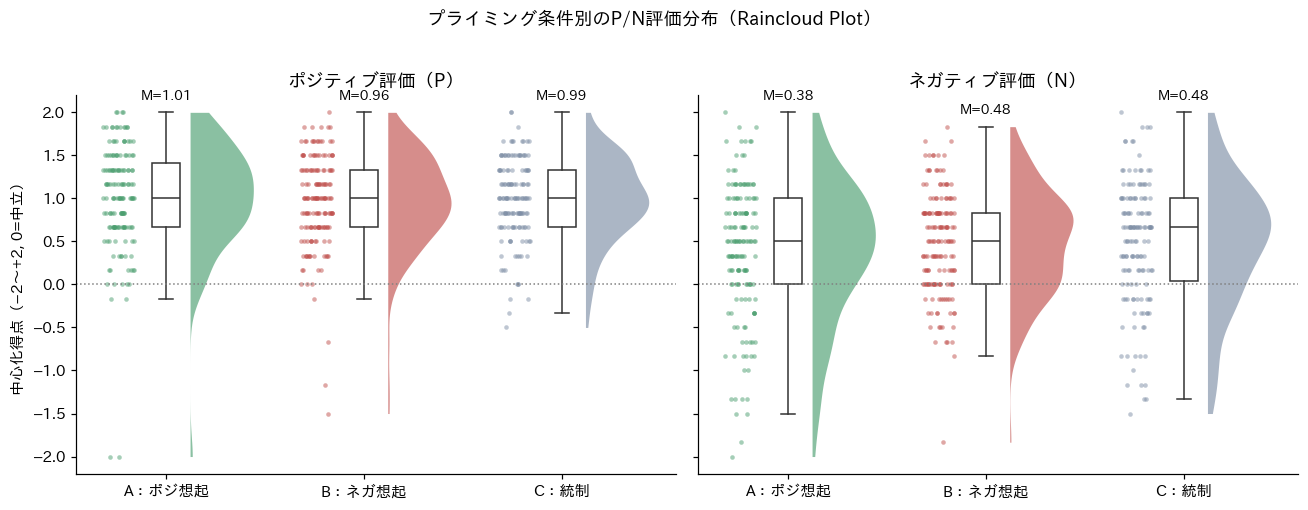

読み取り方: 効果が「なお出ない」場合、それは仮説②の「凝固した構造的両義性」の証拠として解釈できる。
その解釈を主張するには、効果量dの信頼区間が「意味のある効果の範囲」を排除しているか（等価性の観点）も併記すること。


In [ ]:
def raincloud(ax, data_by_group, labels, colors, title='', ylabel=''):
    """半バイオリン＋箱ひげ＋ジッター（Raincloud Plot）"""
    rng = np.random.default_rng(RANDOM_STATE)
    for i, vals in enumerate(data_by_group):
        v = np.asarray(pd.Series(vals).dropna(), dtype=float)
        kde = stats.gaussian_kde(v)
        yy = np.linspace(v.min(), v.max(), 150)
        dens = kde(yy); dens = dens / dens.max() * 0.32
        ax.fill_betweenx(yy, i + 0.12, i + 0.12 + dens, color=colors[i], alpha=.65, lw=0)
        bp = ax.boxplot(v, positions=[i], widths=0.14, patch_artist=True,
                        showfliers=False, manage_ticks=False)
        bp['boxes'][0].set(facecolor='white', edgecolor='.2')
        for el in ('medians','whiskers','caps'):
            for a in bp[el]: a.set(color='.2')
        ax.scatter(i + rng.uniform(-0.32, -0.16, len(v)), v,
                   s=9, color=colors[i], alpha=.5, lw=0)
        ax.text(i, v.max() + 0.15, f'M={v.mean():.2f}', ha='center', fontsize=9)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.spines[['top','right']].set_visible(False)

COND_LABELS = ['A：ポジ想起', 'B：ネガ想起', 'C：統制']
COND_COLORS = ['#4C9F70', '#C0504D', '#7F8FA6']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, dv, t in zip(axes, ['P','N'], ['ポジティブ評価（P）','ネガティブ評価（N）']):
    raincloud(ax, [df[df.cond==k][dv] for k in 'ABC'], COND_LABELS, COND_COLORS,
              title=t, ylabel='中心化得点（−2〜+2, 0=中立）' if dv=='P' else '')
    ax.axhline(0, ls=':', color='gray', lw=1)
plt.suptitle('プライミング条件別のP/N評価分布（Raincloud Plot）', y=1.02)
plt.tight_layout(); plt.savefig('fig_raincloud_PN.png', bbox_inches='tight'); plt.show()

print('読み取り方: 効果が「なお出ない」場合、それは仮説②の「凝固した構造的両義性」の証拠として解釈できる。')
print('その解釈を主張するには、効果量dの信頼区間が「意味のある効果の範囲」を排除しているか（等価性の観点）も併記すること。')

## 7. 道徳的距離化：Q15 自己→社会の勾配
対象が遠くなる（自分→友人→同世代→社会）ほど評価が下がるかを反復測定ANOVAで検証し、Self-Society Gapが条件で伸縮するかを見ます。

,Source,SS,DF,MS,F,p_unc,p_GG_corr,ng2,eps,sphericity,W_spher,p_spher
0,target,553.6959,3,184.5653,205.6309,0.0,0.0,0.1131,0.8522,False,0.7839,0.0
1,Error,1265.5541,1410,0.8976,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,A,B,T,p_corr,hedges
0,q15a_self,q15b_friend,-2.856,0.004,-0.097
1,q15a_self,q15c_peers,13.368,0.000,0.536
2,q15a_self,q15d_society,15.837,0.000,0.733
3,q15b_friend,q15c_peers,16.569,0.000,0.660
4,q15b_friend,q15d_society,18.938,0.000,0.872
5,q15c_peers,q15d_society,5.032,0.000,0.180


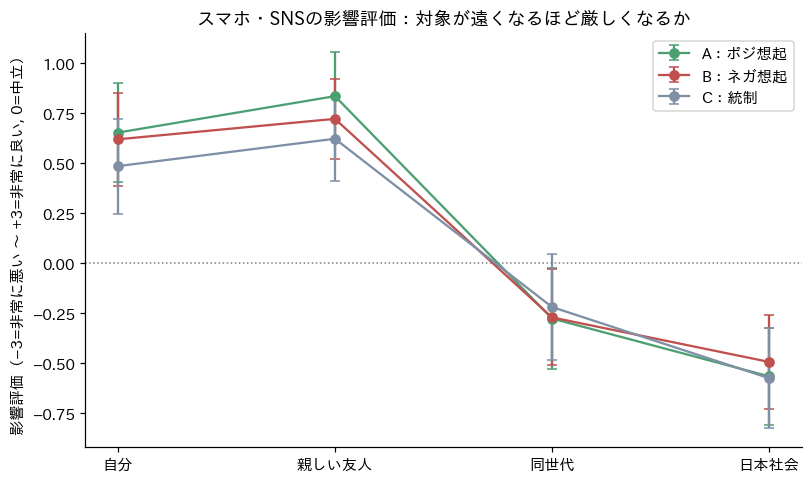


Self-Society Gap（Q15A−Q15D）への条件効果:


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
C(cond)[T.A],0.158,0.178,0.888,0.375,-0.191,0.508
C(cond)[T.B],0.050,0.170,0.292,0.771,-0.284,0.383


In [ ]:
import pingouin as pg

q15_cols = ['q15a_self','q15b_friend','q15c_peers','q15d_society']
q15_labels = ['自分','親しい友人','同世代','日本社会']

long = df[['cond'] + q15_cols].dropna().reset_index().melt(
    id_vars=['index','cond'], value_vars=q15_cols, var_name='target', value_name='score')
aov = pg.rm_anova(data=long, dv='score', within='target', subject='index', detailed=True)
display(aov.round(4))

post = pg.pairwise_tests(data=long, dv='score', within='target', subject='index', padjust='holm')
# バージョン差異対策：補正済みp値の列名を動的に特定（無ければ未補正p値を表示）
pcol = next((c for c in ['p-corr', 'p_corr', 'p-unc', 'p_unc'] if c in post.columns), None)
show_cols = [c for c in ['A', 'B', 'T', pcol, 'hedges'] if c is not None and c in post.columns]
if pcol in ('p-unc', 'p_unc'):
    print('注: このpingouinバージョンでは補正済みp値列が出力されないため、未補正p値を表示しています')
display(post[show_cols].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k, lab, c in zip('ABC', COND_LABELS, COND_COLORS):
    sub = df[df.cond==k][q15_cols]
    means = sub.mean(); sems = sub.sem()
    ax.errorbar(range(4), means, yerr=1.96*sems, marker='o', capsize=3, label=lab, color=c)
ax.axhline(0, ls=':', color='gray', lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(q15_labels)
ax.set_ylabel('影響評価（−3=非常に悪い 〜 +3=非常に良い, 0=中立）')
ax.set_title('スマホ・SNSの影響評価：対象が遠くなるほど厳しくなるか')
ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_q15_gradient.png', bbox_inches='tight'); plt.show()

m_gap = smf.ols('gap_self_soc ~ C(cond) + female + grade + hours', data=df).fit(cov_type='HC3')
print('\nSelf-Society Gap（Q15A−Q15D）への条件効果:')
display(m_gap.summary2().tables[1].loc[['C(cond)[T.A]','C(cond)[T.B]']].round(3))

## 8. LPA：類型化と「両義型」の抽出
標準化したP・Nの2次元得点にガウス混合モデル（LPAと同型）を当て、BIC等でプロファイル数を決めます。その後、**条件→プロファイル所属**の多項ロジットで、プライミングが両義型への所属確率を動かすか（＝両義性は揺らぐのか凝固しているのか）を検証します。

,k,BIC,AIC,entropy,最小クラス%
0,1,2697.900,2681.280,NaN,100.000
1,2,2669.503,2632.109,0.331,17.197
2,3,2637.498,2579.330,0.527,2.760
3,4,2652.832,2573.890,0.575,2.972
4,5,2665.793,2566.076,0.581,0.637
5,6,2696.731,2576.240,0.559,0.637


※実測ではBIC最小はk=3、理論的枠組み（4類型）ではk=4。両方を確認し、本文ではk=4を採用しつつk=3を感度分析に。


,zP,zN,P_c,N_c,profile
0,0.90,-0.42,1.47,0.15,楽観型1
1,-0.58,0.85,0.67,1.04,両義型
2,-1.32,-2.02,0.27,-0.97,無関心型
3,-0.24,0.05,0.86,0.48,楽観型2



プロファイル人数:
profile
楽観型2    231
楽観型1    157
両義型      70
無関心型     13
Name: count, dtype: int64


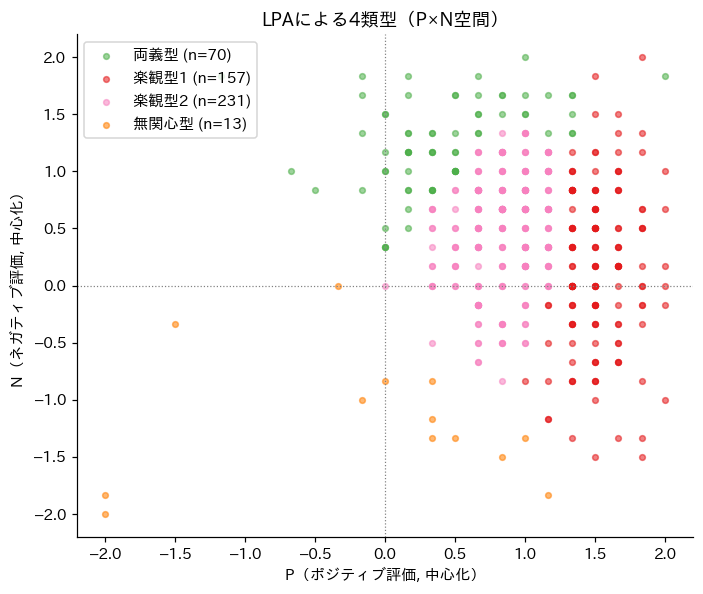

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

lpa_dat = df[['P','N']].dropna()
scaler = StandardScaler().fit(lpa_dat)
Xz = scaler.transform(lpa_dat)

enum_rows = []
for k in range(1, 7):
    gm = GaussianMixture(k, covariance_type='diag', n_init=50, random_state=RANDOM_STATE).fit(Xz)
    post = gm.predict_proba(Xz)
    entropy = 1 - (-(post*np.log(post+1e-12)).sum()) / (len(Xz)*np.log(k)) if k > 1 else np.nan
    enum_rows.append({'k':k, 'BIC':gm.bic(Xz), 'AIC':gm.aic(Xz),
                      'entropy':entropy, '最小クラス%':pd.Series(gm.predict(Xz)).value_counts(normalize=True).min()*100})
enum = pd.DataFrame(enum_rows).round(3)
display(enum)
print('※実測ではBIC最小はk=3、理論的枠組み（4類型）ではk=4。両方を確認し、本文ではk=4を採用しつつk=3を感度分析に。')

N_PROFILES = 4   # ← ここを3に変えれば感度分析
gm = GaussianMixture(N_PROFILES, covariance_type='diag', n_init=100, random_state=RANDOM_STATE).fit(Xz)
lab_raw = gm.predict(Xz)

# プロファイル命名：センターを元の中心化尺度（−2〜+2）に戻し、絶対水準（+0.5を「高」の目安）でラベル
centers = pd.DataFrame(gm.means_, columns=['zP','zN'])
raw_centers = scaler.inverse_transform(gm.means_)
centers['P_c'] = raw_centers[:, 0]; centers['N_c'] = raw_centers[:, 1]
def name_profile(r):
    hiP, hiN = r.P_c >= 0.5, r.N_c >= 0.5
    if hiP and hiN:           return '両義型'
    if hiP and not hiN:       return '楽観型'
    if (not hiP) and hiN:     return '批判型'
    return '無関心型'
centers['profile'] = centers.apply(name_profile, axis=1)
# 同名プロファイルには番号を付けて区別（例: 両義型1, 両義型2）
dup = centers['profile'].duplicated(keep=False)
centers.loc[dup, 'profile'] = centers.loc[dup, 'profile'] + centers.loc[dup].groupby('profile').cumcount().add(1).astype(str)
display(centers.round(2))

df.loc[lpa_dat.index, 'profile'] = centers['profile'].values[lab_raw]
amb_idx = centers.index[centers['profile'].str.startswith('両義')]
if len(amb_idx) > 0:
    df.loc[lpa_dat.index, 'p_amb'] = gm.predict_proba(Xz)[:, amb_idx].sum(axis=1)
else:
    df['p_amb'] = np.nan
    print('注: このk・命名基準では明確な「両義型（P高N高）」クラスタは分離しませんでした。')
    print('   → その場合、両義性の分析は連続指標（amb_griffin等）を主とし、LPAは補助と位置づけるのが誠実です。')
print('\nプロファイル人数:'); print(df['profile'].value_counts())

fig, ax = plt.subplots(figsize=(6.5, 5.5))
palette = dict(zip(centers['profile'], plt.cm.Set1(np.linspace(0, .8, N_PROFILES))))
for pr, g in df.dropna(subset=['profile']).groupby('profile'):
    ax.scatter(g['P'], g['N'], s=14, alpha=.55, label=f'{pr} (n={len(g)})', color=palette[pr])
ax.set_xlabel('P（ポジティブ評価, 中心化）'); ax.set_ylabel('N（ネガティブ評価, 中心化）')
ax.axhline(0, ls=':', color='gray', lw=.8); ax.axvline(0, ls=':', color='gray', lw=.8)
ax.set_title(f'LPAによる{N_PROFILES}類型（P×N空間）'); ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_lpa_profiles.png', bbox_inches='tight'); plt.show()

多項ロジット（基準アウトカム＝ 両義型 ）
                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                  471
Model:                        MNLogit   Df Residuals:                      453
Method:                           MLE   Df Model:                           15
Date:                Mon, 20 Jul 2026   Pseudo R-squ.:                 0.04227
Time:                        23:47:12   Log-Likelihood:                -495.31
converged:                       True   LL-Null:                       -517.17
Covariance Type:            nonrobust   LLR p-value:                 0.0001217
       y=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6680      0.587      1.137      0.255      -0.483       1.819
female        -0.0999      0.341     -0.293      0.770      -0.768       0.569
grade         -0.1518      0.1

,両義型,楽観型1,楽観型2,無関心型
A,NaN,NaN,NaN,NaN
B,NaN,NaN,NaN,NaN
C,NaN,NaN,NaN,NaN


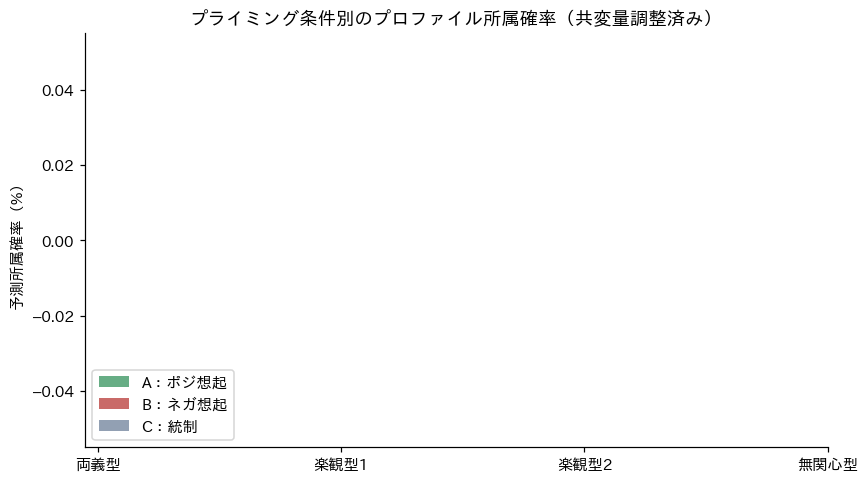

両義系プロファイルの所属確率が条件間でほぼ動かなければ、「凝固した構造的両義性」の直接的証拠。


In [ ]:
# --- 条件 → プロファイル所属の多項ロジット ＋ 予測所属確率 ---
import statsmodels.api as sm

mn_dat = df.dropna(subset=['profile','female','grade','hours']).copy()
mn_dat['profile_cat'] = pd.Categorical(mn_dat['profile'])
y_codes = mn_dat['profile_cat'].cat.codes
X = pd.get_dummies(mn_dat[['cond','female','grade','hours']], columns=['cond'], drop_first=False)
X = X.drop(columns=['cond_C']).astype(float)  # Cを基準
X = sm.add_constant(X)

mnl = sm.MNLogit(y_codes, X).fit(disp=0)
print('多項ロジット（基準アウトカム＝', mn_dat['profile_cat'].cat.categories[0], '）')
print(mnl.summary())

# 予測所属確率（条件のみ変えて他共変量は実測値のまま＝G-computation）
prob_rows = []
for k in 'ABC':
    Xk = X.copy(); Xk['cond_A'] = float(k=='A'); Xk['cond_B'] = float(k=='B')
    pr = mnl.predict(Xk).mean(axis=0)
    prob_rows.append(pr)
probs = pd.DataFrame(prob_rows, index=['A','B','C'], columns=mn_dat['profile_cat'].cat.categories)
display((probs*100).round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(probs.columns)); w = 0.26
for i, (k, c, lab) in enumerate(zip('ABC', COND_COLORS[:3], COND_LABELS)):
    order = {'A':0,'B':1,'C':2}[k]
    ax.bar(x + (order-1)*w, probs.loc[k]*100, width=w, label=lab,
           color=[COND_COLORS[0], COND_COLORS[1], COND_COLORS[2]][order], alpha=.85)
ax.set_xticks(x); ax.set_xticklabels(probs.columns)
ax.set_ylabel('予測所属確率（%）')
ax.set_title('プライミング条件別のプロファイル所属確率（共変量調整済み）')
ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_lpa_margins.png', bbox_inches='tight'); plt.show()
print('両義系プロファイルの所属確率が条件間でほぼ動かなければ、「凝固した構造的両義性」の直接的証拠。')

## 9. 調整された媒介分析（ブートストラップ）＋パス図
**注**：本来の理論モデルの媒介変数「記憶のポジティブ性」はQ2自由記述のコーディングが必要です（→ §9-2参照）。ここではまず、測定済み変数による実行可能なモデルとして
`X＝条件（AまたはB vs C） → M＝自己への影響評価（Q15A） → Y＝N評価`、調整変数 `W＝インフラ強制感（Q13）` を推定します。変数はセル冒頭で差し替え可能です。

In [ ]:
def ols_np(y, X):
    """numpyベースの高速OLS（ブートストラップ用）"""
    X = np.column_stack([np.ones(len(X)), X])
    b = np.linalg.pinv(X.T @ X) @ X.T @ y
    return b

def moderated_mediation(data, x, m, y, w, n_boot=5000, seed=RANDOM_STATE):
    d = data.dropna(subset=[x, m, y, w]).copy()
    d['_wc'] = d[w] - d[w].mean()   # 調整変数は中心化
    rng = np.random.default_rng(seed)
    def paths(dd):
        a  = ols_np(dd[m].values.astype(float), dd[[x]].values.astype(float))[1]           # X→M
        Xy = np.column_stack([dd[m], dd[x], dd['_wc'], dd[m]*dd['_wc']]).astype(float)
        bb = ols_np(dd[y].values.astype(float), Xy)                                        # M,X,W,M×W→Y
        return np.array([a*bb[1],        # 間接効果（W=平均）
                         a*bb[4],        # Index of Moderated Mediation（a×b_MW）
                         bb[2]])         # 直接効果 c'
    point = paths(d)
    idx = np.arange(len(d))
    boots = np.array([paths(d.iloc[rng.choice(idx, len(d), replace=True)]) for _ in range(n_boot)])
    ci = np.percentile(boots, [2.5, 97.5], axis=0).T
    out = pd.DataFrame({'推定値': point, 'CI下限': ci[:,0], 'CI上限': ci[:,1]},
                       index=['間接効果 a×b（W=平均）', 'Index of Mod. Mediation', '直接効果 c\''])
    out['有意(CI≠0)'] = np.sign(out['CI下限']) == np.sign(out['CI上限'])
    return out.round(3), d

# ==== ここを差し替えて別モデルも検証可能 ====
MED_M, MED_Y, MED_W = 'q15a_self', 'N', 'q13'
for treat, tl in [('A', 'A（ポジ想起）'), ('B', 'B（ネガ想起）')]:
    sub = df[df.cond.isin([treat, 'C'])].copy()
    sub['x'] = (sub.cond == treat).astype(int)
    res, dd = moderated_mediation(sub, 'x', MED_M, MED_Y, MED_W)
    print(f'\n■ {tl} vs C（n={len(dd)}）  X→[{MED_M}]→[{MED_Y}], W=[{MED_W}]')
    display(res)


■ A（ポジ想起） vs C（n=305）  X→[q15a_self]→[N], W=[q13]


,推定値,CI下限,CI上限,有意(CI≠0)
間接効果 a×b（W=平均）,-0.022,-0.077,0.023,False
Index of Mod. Mediation,-0.003,-0.028,0.021,False
直接効果 c',-0.077,-0.235,0.091,False



■ B（ネガ想起） vs C（n=312）  X→[q15a_self]→[N], W=[q13]


,推定値,CI下限,CI上限,有意(CI≠0)
間接効果 a×b（W=平均）,-0.017,-0.063,0.025,False
Index of Mod. Mediation,0.004,-0.011,0.026,False
直接効果 c',0.016,-0.123,0.159,False


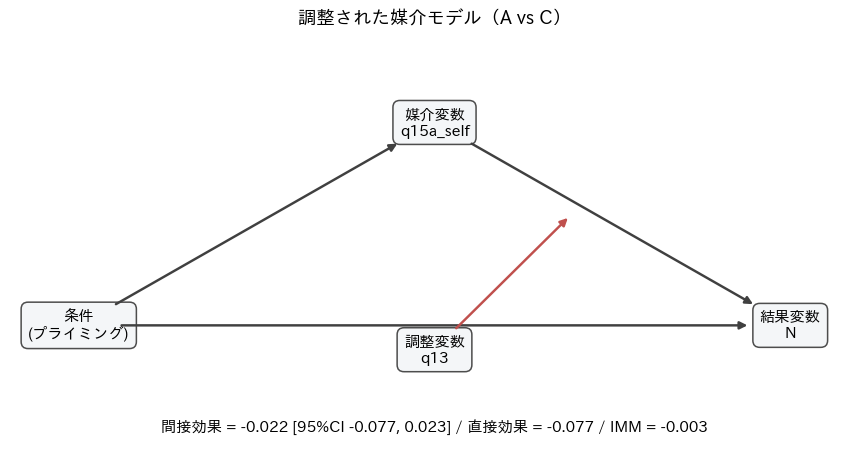

In [ ]:
# --- パス図（DAG）を描画 ---
def draw_dag(res, title):
    fig, ax = plt.subplots(figsize=(8, 4.2)); ax.axis('off')
    box = dict(boxstyle='round,pad=0.45', fc='#F4F6F8', ec='.3')
    pos = {'X': (0.08, 0.28), 'M': (0.50, 0.78), 'Y': (0.92, 0.28), 'W': (0.50, 0.22)}
    txt = {'X': '条件\n(プライミング)', 'M': f'媒介変数\n{MED_M}', 'Y': f'結果変数\n{MED_Y}', 'W': f'調整変数\n{MED_W}'}
    for k, (x_, y_) in pos.items():
        ax.text(x_, y_, txt[k], ha='center', va='center', bbox=box, fontsize=10)
    arr = dict(arrowstyle='-|>', color='.25', lw=1.6, shrinkA=28, shrinkB=28)
    ax.annotate('', xy=pos['M'], xytext=pos['X'], arrowprops=arr)
    ax.annotate('', xy=pos['Y'], xytext=pos['M'], arrowprops=arr)
    ax.annotate('', xy=pos['Y'], xytext=pos['X'], arrowprops=arr)
    ax.annotate('', xy=(0.66, 0.55), xytext=pos['W'], arrowprops=dict(arrowstyle='-|>', color='#C0504D', lw=1.6, shrinkA=20))
    ie, imm, de = res['推定値']
    lo, hi = res.loc['間接効果 a×b（W=平均）', ['CI下限','CI上限']]
    ax.text(0.5, 0.02, f'間接効果 = {ie:.3f} [95%CI {lo:.3f}, {hi:.3f}] / 直接効果 = {de:.3f} / IMM = {imm:.3f}',
            ha='center', fontsize=10)
    ax.set_title(title)
    plt.tight_layout(); plt.show()

sub = df[df.cond.isin(['A','C'])].copy(); sub['x'] = (sub.cond=='A').astype(int)
resA, _ = moderated_mediation(sub, 'x', MED_M, MED_Y, MED_W)
draw_dag(resA, '調整された媒介モデル（A vs C）')

### 9-2. 「記憶のポジティブ性」を使う場合（オプション）
理論モデルどおり媒介変数を**Q2自由記述の感情価**にするには、`q2_text` を人手または辞書法でコーディングした列（例: `memory_valence`、-1〜+1）を作成し、上のセルの `MED_M = 'memory_valence'` に差し替えて再実行してください。以下は下書き用の書き出しセルです。

In [ ]:
# Q2自由記述をコーディング用にエクスポート（Excelで開いて感情価を手入力→再読込）
df[['cond','q2_text']].dropna(subset=['q2_text']).to_csv('q2_texts_for_coding.csv', index=True)
print('q2_texts_for_coding.csv を出力しました（index列をキーに memory_valence を追記して結合してください）')

## 10. Specification Curve Analysis：両義性 → 孤独感の頑健性
両義性の**操作化3通り**（Griffin指数・min(P,N)・P×N）×**統制変数6個の全組み合わせ**（2⁶=64通り）＝**192仕様**をすべて推定し、「どんな前提でも両義性には孤独というコストが伴う」かを検証します。

In [ ]:
def ols_hc3_np(y, X):
    """numpyベースのHC3頑健OLS（高速・SCA用）"""
    X = np.column_stack([np.ones(len(X)), X])
    XtXi = np.linalg.pinv(X.T @ X)
    b = XtXi @ X.T @ y
    e = y - X @ b
    h = np.einsum('ij,jk,ik->i', X, XtXi, X)
    u2 = (e / (1 - h))**2
    V = XtXi @ (X.T * u2) @ X @ XtXi
    se = np.sqrt(np.diag(V))
    t = np.divide(b, se, out=np.zeros_like(b), where=se > 0)
    p = 2 * stats.t.sf(np.abs(t), len(y) - X.shape[1])
    return b, se, p

AMB_DEFS = {'Griffin指数': 'amb_griffin', 'min(P,N)': 'amb_min', 'P×N': 'amb_prod'}
SCA_CONTROLS = ['female', 'grade', 'hours', 'native', 'line_n', 'habit']
SCA_DV = 'lonely'

d0 = df.dropna(subset=[SCA_DV] + list(AMB_DEFS.values()) + SCA_CONTROLS).copy()
specs = []
for def_name, col in AMB_DEFS.items():
    z = ((d0[col] - d0[col].mean()) / d0[col].std()).values
    for r in range(len(SCA_CONTROLS) + 1):
        for cs in combinations(SCA_CONTROLS, r):
            Xmat = np.column_stack([z] + [d0[c].values.astype(float) for c in cs]) if cs else z.reshape(-1, 1)
            b, se, p = ols_hc3_np(d0[SCA_DV].values.astype(float), Xmat)
            specs.append({'定義': def_name, 'beta': b[1], 'se': se[1], 'p': p[1],
                          **{c: (c in cs) for c in SCA_CONTROLS}})
sca = pd.DataFrame(specs).sort_values('beta').reset_index(drop=True)
print(f'総仕様数: {len(sca)} / β中央値 = {sca.beta.median():.3f} / '
      f'p<.05: {(sca.p < .05).mean():.0%} / 正の効果: {(sca.beta > 0).mean():.0%}')

総仕様数: 192 / β中央値 = 0.253 / p<.05: 100% / 正の効果: 100%


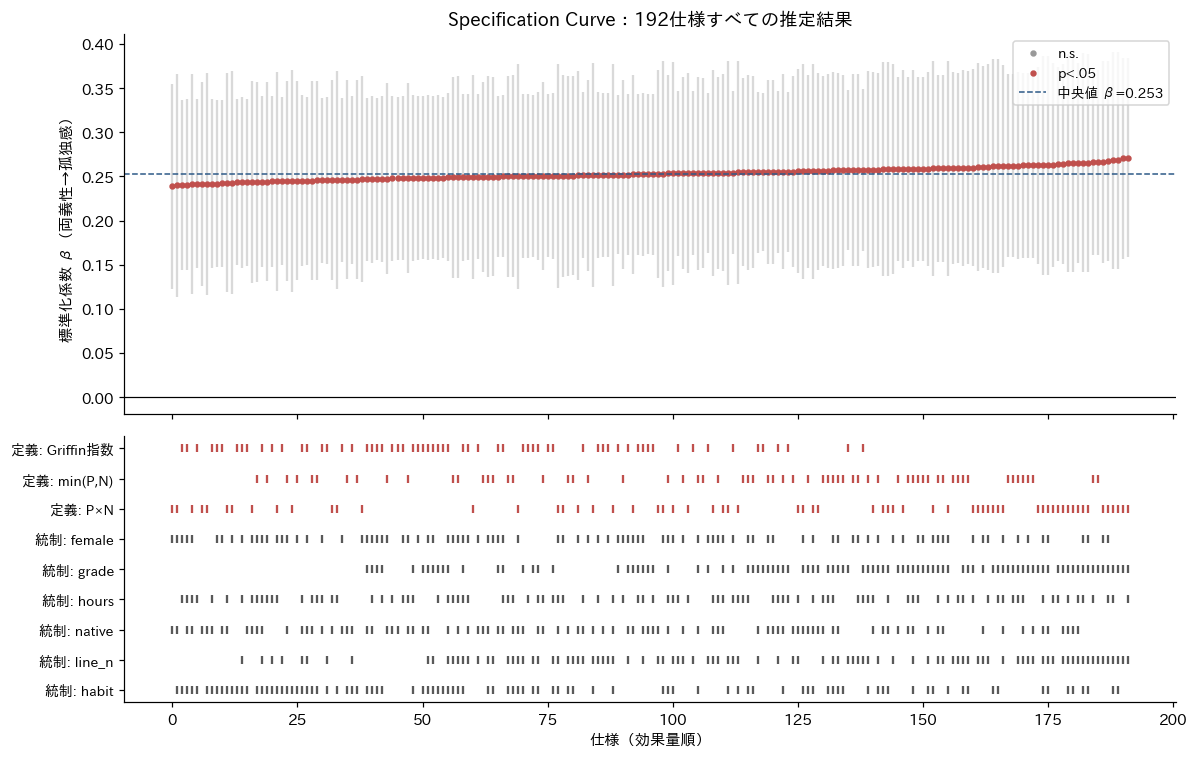

感度分析（フラグ行除外, n=466）: β=0.249, p=0.0000


In [ ]:
# --- 仕様曲線図（上段: 効果量、下段: 仕様ダッシュボード）---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1.4]})
xpos = np.arange(len(sca))
sig = sca.p < .05
ax1.errorbar(xpos, sca.beta, yerr=1.96*sca.se, fmt='none', ecolor='.85', zorder=1)
ax1.scatter(xpos[~sig], sca.beta[~sig], s=10, color='.6', label='n.s.', zorder=2)
ax1.scatter(xpos[sig], sca.beta[sig], s=10, color='#C0504D', label='p<.05', zorder=2)
ax1.axhline(0, color='k', lw=.8)
ax1.axhline(sca.beta.median(), color='#2E5A88', ls='--', lw=1,
            label=f'中央値 β={sca.beta.median():.3f}')
ax1.set_ylabel('標準化係数 β（両義性→孤独感）')
ax1.set_title(f'Specification Curve：{len(sca)}仕様すべての推定結果')
ax1.legend(fontsize=9); ax1.spines[['top','right']].set_visible(False)

dash_rows = list(AMB_DEFS.keys()) + SCA_CONTROLS
for yi, rname in enumerate(dash_rows):
    if rname in AMB_DEFS:
        mask = (sca['定義'] == rname).values
    else:
        mask = sca[rname].values
    ax2.scatter(xpos[mask], np.full(mask.sum(), yi), marker='|', s=28,
                color='#C0504D' if rname in AMB_DEFS else '.35')
ax2.set_yticks(range(len(dash_rows)))
ax2.set_yticklabels([f'定義: {r}' if r in AMB_DEFS else f'統制: {r}' for r in dash_rows], fontsize=9)
ax2.set_xlabel('仕様（効果量順）'); ax2.invert_yaxis()
ax2.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_specification_curve.png', bbox_inches='tight'); plt.show()

# 感度分析: 品質フラグ行を除外しても保持されるか
d1 = d0[(d0.flag_straight == 0) & (d0.flag_influencer == 0)]
z = ((d1['amb_griffin'] - d1['amb_griffin'].mean()) / d1['amb_griffin'].std()).values
b, se, p = ols_hc3_np(d1['lonely'].values.astype(float),
                      np.column_stack([z] + [d1[c].values.astype(float) for c in SCA_CONTROLS]))
print(f'感度分析（フラグ行除外, n={len(d1)}）: β={b[1]:.3f}, p={p[1]:.4f}')

## 11. 成果物のダウンロード

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

# ZIPにまとめる成果物
outputs = [
    'cleaned_combined.csv',
    'fig_raincloud_PN.png',
    'fig_q15_gradient.png',
    'fig_lpa_profiles.png',
    'fig_lpa_margins.png',
    'fig_specification_curve.png',
]

# 実際に存在するファイルを確認
existing = [Path(f) for f in outputs if Path(f).is_file()]
missing = [f for f in outputs if not Path(f).is_file()]

if not existing:
    raise FileNotFoundError('ZIPにまとめられる成果物がありません。')

# 前回の処理で残った不完全なZIPを削除
archive_path = Path('analysis_outputs.zip')
archive_path.unlink(missing_ok=True)

# 指定した成果物だけをZIP化
with ZipFile(
    archive_path,
    mode='w',
    compression=ZIP_DEFLATED,
    allowZip64=True,
) as zip_file:
    for path in existing:
        zip_file.write(path, arcname=path.name)
        print(f'✓ {path.name}')

size_mb = archive_path.stat().st_size / 1024**2

print()
print(
    f'✅ {len(existing)}個の成果物を '
    f'{archive_path.name} にまとめました（{size_mb:.1f} MB）。'
)

if missing:
    print('⚠️ 見つからなかったファイル:', ', '.join(missing))

from google.colab import files
files.download('analysis_outputs.zip')

✓ cleaned_combined.csv
✓ fig_raincloud_PN.png
✓ fig_q15_gradient.png
✓ fig_lpa_profiles.png
✓ fig_lpa_margins.png
✓ fig_specification_curve.png

✅ 6個の成果物を analysis_outputs.zip にまとめました（0.3 MB）。


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 付録：解釈のためのチェックリスト
1. **仮説①（言説の測定論的脱構築）** → §6のATE。ネガ想起（B）でNが上がる／ポジ想起（A）でNが下がるなら「問い方が評価を作る」証拠。動かなければ言説の効果は限定的。
2. **仮説②（両義性は凝固か揺らぎか）** → §6＋§8。条件が両義型所属確率を動かさない＝**凝固した構造的両義性**。ただし「効果がない」の主張には効果量CIによる等価性の検討を必ず添える。
3. **仮説③（道徳的距離化の文脈依存性）** → §7。自己→社会の勾配の存在と、Gapが条件で伸縮するか。
4. **両義性のコスト** → §10のSCA。全仕様で正なら「両義型には孤独が伴う」を頑健に主張できる。
5. 主要な結論は**フラグ行除外**・**P_core4版**・**LPA k=3版**でも再現するか確認する。